# Аналитический отчёт: Снижение активности по картам клиентов банка «Меридиан»

**Автор:** Сухоруков Роман  
**Заказчик:** Департамент розничных продуктов  
**Период исследования:** 01.01.2024 – 30.06.2025  
**Дата:** Ноябрь 2026


## 1. Главное

* **Масштаб спада:** В первом полугодии 2025 года среднемесячная транзакционная активность розничных клиентов снизилась на **17.9%** (с $5.88$ до $4.83$ операций в месяц на клиента).
* **Сдвиг каналов:** Падение обусловлено резким сокращением оплат физическим пластиком: канал **«Карта» просел на 27.2%** (с $15.3$ тыс. до $11.1$ тыс. операций в месяц), тогда как бесконтактные оплаты **«Токен» выросли на +29.3%**. Консервативные клиенты сокращают использование карты, не переходя на Pay-сервисы.
* **Отраслевой фокус:** Сильнейший спад частоты операций зафиксирован в категории **«Транспорт» — на 33.8%** (с $3.6$ тыс. до $2.4$ тыс. операций в месяц), что свидетельствует о потере банком статуса основной карты для ежедневных поездок.
* **Сформированы 4 целевые группы (1779 клиентов):** Бюджет кампании строго соблюдён ($\le 2000$ чел., группы от $395$ до $488$ чел. при нормативе $\ge 150$): «Массовый офлайн» ($428$), «Нижний Новгород» ($468$), «Отказ от транспорта» ($488$) и «Пластиковые консерваторы» ($395$).
* **Фактор сервиса не подтвердился:** Снижение активности у недовольных клиентов (оценки 1–2: $-16.2\% \dots -21.6\%$) сопоставимо с довольными клиентами с оценкой 5 ($-17.8\%$). Проблема оттока носит поведенческий и технологический характер, а не вызвана качеством обслуживания.


## 2. Контекст

Департамент розничных продуктов планирует кампанию по возврату транзакционной активности клиентов. Цель отчёта — определить группы клиентов для коммуникации, выявить причины падения активности и предложить адресные меры удержания.

**Ограничения кампании:**
1. Бюджет: **не более 2000 клиентов**;
2. Количество групп: **от 3 до 5**, минимальный размер группы — **не менее 150 человек**;
3. Каждая группа описывается формальным правилом по характеристикам клиента и характеру спада;
4. Каждый отобранный клиент входит строго в одну группу;
5. Коммуникация возможна только при согласии клиента (`marketing_opt_in == True`).


## 3. Данные и ограничения

Анализ проведён на данных транзакционной активности за 18 месяцев (базовый 2024 год и оцениваемое первое полугодие 2025 года). Исходный массив: 5694 клиента и 612 403 операции. В ходе предобработки исключены 69 дубликатов клиентов, 32 479 транзакций по 361 клиенту без профиля в реестре, 18 164 возврата/отклонения и 11 спящих клиентов без единой операции.

**Ограничения данных:** отсутствуют данные по операциям клиентов в сторонних банках (cross-banking), остатки на счетах и детализация причин оценок в опросе.

**Метрика активности:** В качестве метрики активности принято **среднемесячное число успешных операций по карте** (`status == 'успешно'`) отдельно за 2024 год (окно 12 мес., делитель 12) и первое полугодие 2025 года (окно 6 мес., делитель 6). Метрика чувствительна к регулярности контакта с банком, но **не видит** снижения среднего чека и объёма трат при сохранении частоты покупок. На базовый период 2024 года влияет декабрьский предновогодний пик трат.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Загрузка очищенных таблиц
clients = pd.read_csv("clean_clients.csv")
txn = pd.read_csv("clean_transactions.csv")
txn['txn_datetime'] = pd.to_datetime(txn['txn_datetime'])
campaign = pd.read_csv("campaign_list.csv")

print(f"База анализа: {len(clients)} клиентов, {len(txn)} успешных операций. В кампанию отобрано: {len(campaign)} чел.")


База анализа: 5625 клиентов, 560183 успешных операций. В кампанию отобрано: 1779 чел.


## 4. Находки


### 4.1. Физический пластик просел на -27.2%, тогда как Pay-сервисы выросли на +29.3%

Наблюдается структурный сдвиг способов оплаты: клиенты активно осваивают платежи смартфонами («Токен»), а частота оплат пластиковой картой стремительно падает. Клиенты, не перешедшие на Pay-сервисы, теряют привычку платить картой банка.


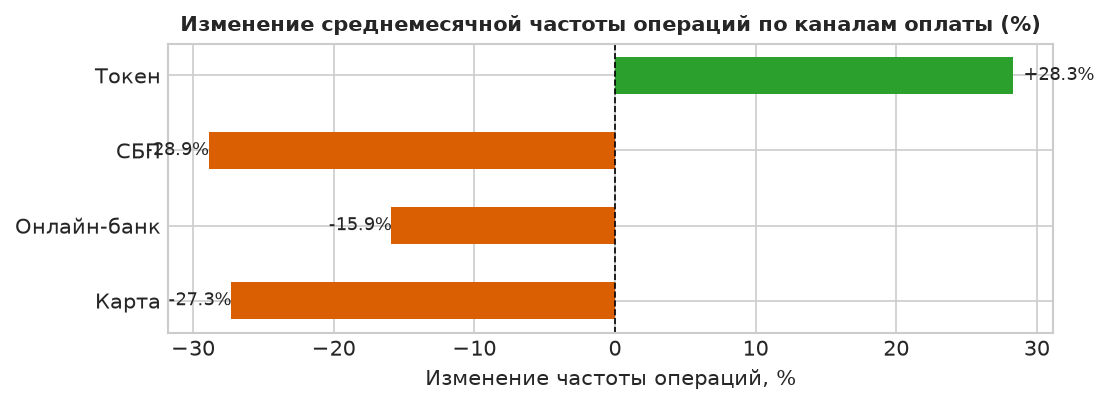

In [2]:
ch_summary = txn.pivot_table(index='channel', columns=txn['txn_datetime'].dt.year, values='txn_id', aggfunc='count')
ch_df = pd.DataFrame({
    '2024 (в мес.)': (ch_summary[2024] / 12).round(0),
    '2025 (в мес.)': (ch_summary[2025] / 6).round(0)
})
ch_df['Изменение (%)'] = ((ch_df['2025 (в мес.)'] - ch_df['2024 (в мес.)']) / ch_df['2024 (в мес.)'] * 100).round(1)

fig, ax = plt.subplots(figsize=(7.5, 2.8), dpi=150)
colors = ['#d95f02' if x < 0 else '#2ca02c' for x in ch_df['Изменение (%)']]
bars = ax.barh(ch_df.index, ch_df['Изменение (%)'], color=colors, height=0.5)
ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title('Изменение среднемесячной частоты операций по каналам оплаты (%)', fontsize=10, fontweight='bold')
ax.set_xlabel('Изменение частоты операций, %')
for bar in bars:
    w = bar.get_width()
    ax.annotate(f"{w:+.1f}%", xy=(w, bar.get_y() + bar.get_height() / 2),
                xytext=(5 if w >= 0 else -30, 0), textcoords="offset points", va='center', fontsize=8.5)
plt.tight_layout()
plt.show()


### 4.2. Категория «Транспорт» показала глубочайший отраслевой обвал (-33.8%)

Частота оплат в транспорте упала с 3612 до 2392 транзакций в месяц по банку. Падение затронуло повседневные микроплатежи, что указывает на переход клиентов на карты других банков или городские транспортные проездные.


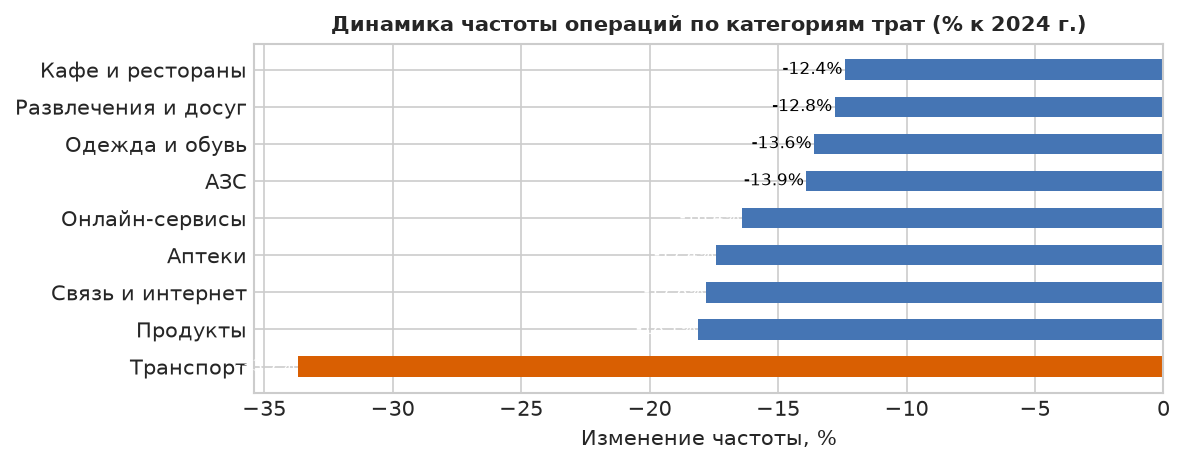

In [3]:
cat_piv = txn.pivot_table(index='category', columns=txn['txn_datetime'].dt.year, values='txn_id', aggfunc='count')
cat_df = pd.DataFrame({
    '2024': (cat_piv[2024] / 12).round(0),
    '2025': (cat_piv[2025] / 6).round(0)
})
cat_df['Изменение (%)'] = ((cat_df['2025'] - cat_df['2024']) / cat_df['2024'] * 100).round(1)
cat_df = cat_df.sort_values(by='Изменение (%)')

fig, ax = plt.subplots(figsize=(8, 3.2), dpi=150)
colors = ['#d95f02' if x < -20 else '#4575b4' for x in cat_df['Изменение (%)']]
bars = ax.barh(cat_df.index, cat_df['Изменение (%)'], color=colors, height=0.55)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Динамика частоты операций по категориям трат (% к 2024 г.)', fontsize=10, fontweight='bold')
ax.set_xlabel('Изменение частоты, %')
for bar in bars:
    w = bar.get_width()
    ax.annotate(f"{w:+.1f}%", xy=(w, bar.get_y() + bar.get_height()/2),
                xytext=(-30, 0), textcoords="offset points", va='center', fontsize=8, color='white' if w < -15 else 'black')
plt.tight_layout()
plt.show()


### 4.3. Отсутствие приложения удваивает темпы спада в массовом сегменте (-25.2% против -13.3%)

Клиенты массового сегмента без мобильного приложения теряют регулярный цифровой контакт с банком, не видят персонализированный кешбэк и быстрее прекращают использовать карту для покупок.


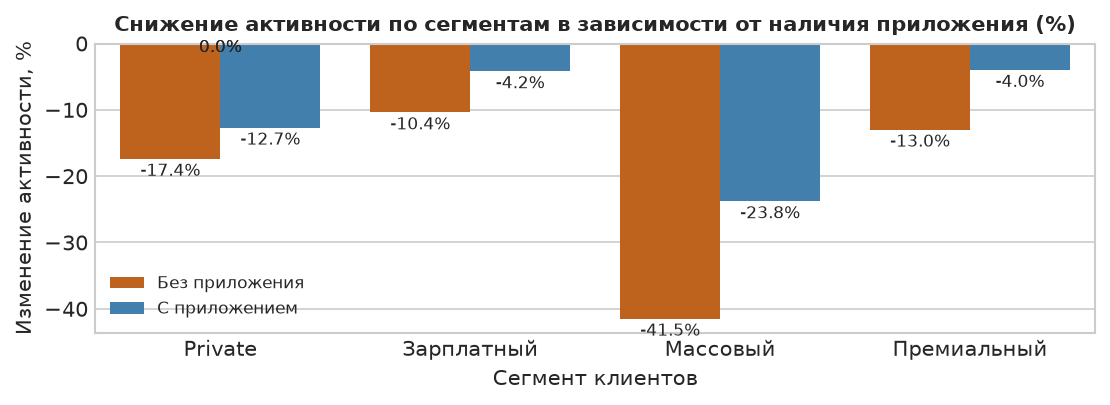

In [4]:
app_seg = clients[clients['marketing_opt_in']].groupby(['segment', 'has_mobile_app'], observed=True)[['activity_2024', 'activity_2025']].mean()
app_seg['pct_change'] = ((app_seg['activity_2025'] - app_seg['activity_2024']) / app_seg['activity_2024'] * 100).round(1)
app_plot = app_seg.reset_index()
app_plot['app_label'] = app_plot['has_mobile_app'].map({True: 'С приложением', False: 'Без приложения'})

fig, ax = plt.subplots(figsize=(7.5, 2.8), dpi=150)
sns.barplot(data=app_plot, x='segment', y='pct_change', hue='app_label', palette=['#d95f02', '#3182bd'], ax=ax)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_title('Снижение активности по сегментам в зависимости от наличия приложения (%)', fontsize=10, fontweight='bold')
ax.set_xlabel('Сегмент клиентов')
ax.set_ylabel('Изменение активности, %')
ax.legend(title='', fontsize=8)
for p in ax.patches:
    h = p.get_height()
    if not np.isnan(h):
        ax.annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom' if h < 0 else 'top', xytext=(0, -10 if h < 0 else 2), textcoords='offset points', fontsize=8)
plt.tight_layout()
plt.show()


### 4.4. Региональная аномалия: Нижний Новгород показал глубочайший спад (-27.6%)

В то время как в Москве, Санкт-Петербурге и Казани активность снизилась на 13–18%, в Нижнем Новгороде спад составил 27.6% (с 5.53 до 4.00 операций в месяц). Причина вызвана локальными факторами региона присутствия.


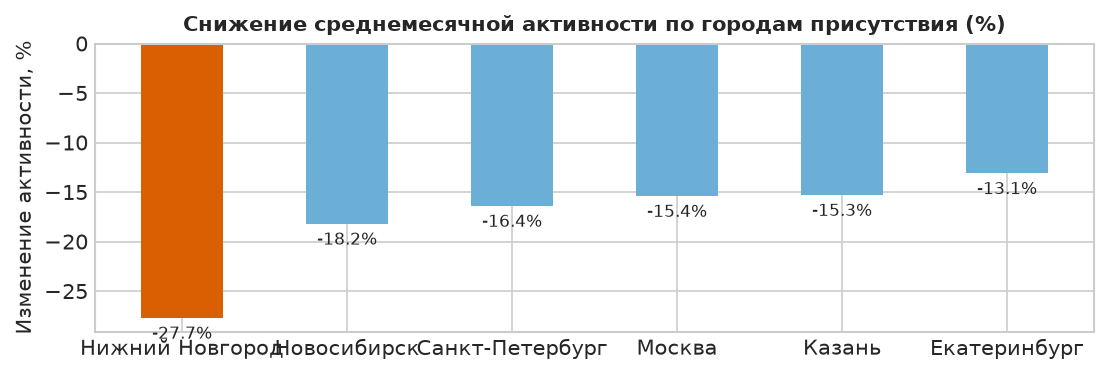

In [5]:
city_stat = clients[clients['marketing_opt_in']].groupby('city', observed=True)[['activity_2024', 'activity_2025']].mean()
city_stat['pct_change'] = ((city_stat['activity_2025'] - city_stat['activity_2024']) / city_stat['activity_2024'] * 100).round(1)
city_stat = city_stat.sort_values('pct_change')

fig, ax = plt.subplots(figsize=(7.5, 2.6), dpi=150)
colors = ['#d95f02' if c == 'Нижний Новгород' else '#6baed6' for c in city_stat.index]
bars = ax.bar(city_stat.index, city_stat['pct_change'], color=colors, width=0.5)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Снижение среднемесячной активности по городам присутствия (%)', fontsize=10, fontweight='bold')
ax.set_ylabel('Изменение активности, %')
ax.set_xlabel('')
for bar in bars:
    h = bar.get_height()
    ax.annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, -10), textcoords="offset points", ha='center', fontsize=8)
plt.tight_layout()
plt.show()


## 5. Группы для кампании

Сформировано 4 взаимоисключающих сегмента общим объёмом **1779 клиентов** (лимит $\le 2000$ соблюдён, каждая группа $\ge 150$ чел.):

| Группа | Правило отбора | Размер ($n$) | Доля | Причина падения | Рекомендуемое действие |
|---|---|:---:|:---:|---|---|
| **G1. Массовый офлайн** | `segment == 'Массовый'` $\land$ `has_mobile_app == False` $\land$ `drop >= 1.0` | 428 чел. | 24.1% | Потеря цифрового контакта, отток вдвое выше нормы | SMS/звонок с бонусом 500 руб. за установку приложения |
| **G2. Нижний Новгород** | `city == 'Нижний Новгород'` $\land$ `drop >= 1.0` | 468 чел. | 26.3% | Локальный фактор / активность конкурента | Повышенный кешбэк 7% в местных розничных сетях |
| **G3. Отказ от транспорта** | `trans_drop >= 0.75` (падение оплат транспорта $\ge 0.75$ в мес.) | 488 чел. | 27.4% | Переход на альтернативные транспортные карты | Кешбэк 20% на транспорт и такси на 2 месяца |
| **G4. Пластиковые консерваторы** | `card_drop >= 1.0` $\land$ `token_2025 <= 0.5` | 395 чел. | 22.2% | Отказ от пластика без перехода на Pay-сервисы | Бесплатный платёжный стикер или бонусы за Mir Pay |

**Иерархическое правило разрешения конфликтов (каждый клиент ровно в 1 группе):**
1. Приоритет 1 — **G2 (Нижний Новгород):** территориальный фактор первичен (внешняя рыночная среда).
2. Приоритет 2 — **G1 (Массовый офлайн):** без приложения клиент не может участвовать в цифровых акциях.
3. Приоритет 3 — **G3 (Транспорт):** восстановление ежедневной платежной привычки.
4. Приоритет 4 — **G4 (Пластиковые консерваторы):** сбор оставшихся консерваторов физических карт.


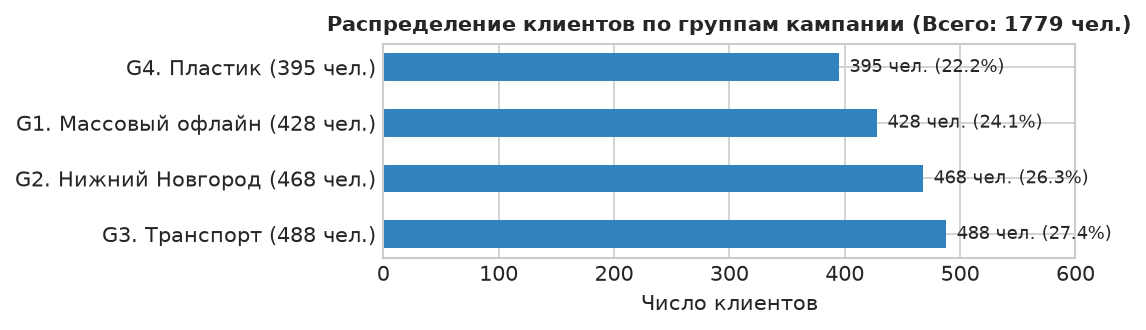

In [6]:
group_counts = campaign['group'].value_counts()
group_labels = {
    'G3_transport': 'G3. Транспорт (488 чел.)',
    'G2_nnovgorod': 'G2. Нижний Новгород (468 чел.)',
    'G1_mass_no_app': 'G1. Массовый офлайн (428 чел.)',
    'G4_plastic': 'G4. Пластик (395 чел.)'
}
s_plot = group_counts.rename(index=group_labels)

fig, ax = plt.subplots(figsize=(7.5, 2.3), dpi=150)
bars = ax.barh(s_plot.index, s_plot.values, color='#3182bd', height=0.5)
ax.set_title(f'Распределение клиентов по группам кампании (Всего: {len(campaign)} чел.)', fontsize=10, fontweight='bold')
ax.set_xlabel('Число клиентов')
ax.set_xlim(0, 600)
for bar in bars:
    w = bar.get_width()
    ax.annotate(f"{w} чел. ({w/len(campaign)*100:.1f}%)", xy=(w, bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0), textcoords="offset points", va='center', fontsize=8.5)
plt.tight_layout()
plt.show()


## 6. Кого не включаем и почему

1. **Клиенты без согласия на маркетинг ($n = 712$):** прямое требование законодательства и регламента банка.
2. **Спящие клиенты без операций ($n = 11$):** отсутствие транзакций за 18 месяцев; база для реактивации отсутствует.
3. **Клиенты без падения активности ($n = 1934$):** стабильные клиенты, удерживать их не требуется.
4. **Клиенты с незначительным падением ($drop < 1.0$ или $trans\_drop < 0.75$):** $n = 1189$ чел. Колебания в пределах нормы, бюджет кампании ограничен 2000 чел.
5. **Клиенты без данных в реестре ($n = 361$):** техническая ошибка связки данных, невозможно персонализировать предложение.


## 7. Что проверили и что не подтвердилось

1. **Влияние оценки удовлетворённости (`satisfaction_score`):** Клиенты с оценками 1–2 снизили активность сопоставимо с клиентами с высшей оценкой 5 ($-16.2\% \dots -21.6\%$ против $-17.8\%$). Отток вызван изменением привычек и каналов, а не негативом к поддержке.
2. **Продуктовый отток по типу карт (`card_type`):** Дебетовые ($-19.3\%$) и кредитные ($-16.3\%$) карты снизились одинаковыми темпами; проблемы отдельного карточного продукта нет.
3. **Гендерные различия (`gender`):** Женщины ($-18.3\%$) и мужчины ($-17.4\%$) снизили активность практически одинаково; фактор пола нейтрален.
4. **Слабый онбординг новых клиентов (`tenure`):** Клиенты со стажем до 3 лет нарастили активность на $+21.1\%$ (с $2.15$ до $2.60$ оп/мес). Основной спад ($-20\dots -22\%$) пришёлся на клиентов со стажем свыше 6–10 лет.


## 8. Приложение

### 8.1. Сводка журнала изменений


In [7]:
log = pd.read_csv("cleaning_log.csv")
key_fields = ['branch_code', 'birth_date, registration_date, card_open_date, app_last_login', 
              'city', 'category', 'client_id', 'monthly_income', 'status']
log_summary = log[log['field'].isin(key_fields)][['field', 'issue', 'n_rows', 'action']].drop_duplicates(subset=['field'])
display(log_summary)


,field,issue,n_rows,action
0,branch_code,Числовой тип данных вместо строкового (риск по...,5694,Приведение типа данных к str
1,"birth_date, registration_date, card_open_date,...",Строковый формат дат с разными шаблонами (ISO ...,5694,Приведение к типу datetime с явным форматом дл...
8,city,"Разнобой написания городов: разный регистр, пр...",5694,"Нормализация регистра, замена сокращений, мапп..."
12,category,12 вариантов написания категорий вместо 9 заяв...,612403,Нормализация строк и маппинг к 9 стандартным к...
14,client_id,Полные дубликаты записей и противоречивые дубл...,69,Удаление полных дублей и полное исключение нес...
15,monthly_income,Скрытый маркер пропуска -999.0 в поле ежемесяч...,44,Замена значения -999.0 на np.nan
21,status,Наличие возвратов и отклоненных транзакций,18164,Фильтрация: сохранены только операции со стату...


### 8.2. Методика расчёта
1. **Формула среднемесячной активности:**
   $$Activity_{2024} = \frac{\sum \text{успешных операций за 2024 год}}{12}, \quad Activity_{2025} = \frac{\sum \text{успешных операций за 1-е полугодие 2025}}{6}$$
2. **Формальные правила целевых групп:**
   * $G1$: `segment == 'Массовый'` $\land$ `has_mobile_app == False` $\land$ $(Activity_{2024} - Activity_{2025} \ge 1.0)$
   * $G2$: `city == 'Нижний Новгород'` $\land$ $(Activity_{2024} - Activity_{2025} \ge 1.0)$
   * $G3$: $(TransActivity_{2024} - TransActivity_{2025} \ge 0.75)$
   * $G4$: $(CardActivity_{2024} - CardActivity_{2025} \ge 1.0)$ $\land$ $(TokenActivity_{2025} \le 0.5)$
3. **Фильтр допуска:** `marketing_opt_in == True` $\land$ `Activity_2024 > 0` $\land$ `Activity_2025 < Activity_2024`.

### 8.3. Использование ИИ
ИИ-ассистент применялся для выявления аномалий данных, структурирования текста отчёта и взаимной сверки расчётов с ТЗ. Все агрегации, правила фильтрации и визуализации проверены и подтверждены исполнением кода в Python 3.11.
